# RBC Fig.9 케이스별 시각화

`paths` 리스트에 **런 디렉터리 경로만** 넣으면 케이스별로 자동 로드·플롯한다.

- **§1 `monitor.csv`** — 시계열 진단 (`Theta_c`, `Nu`, `dt`, `div`). 재시작으로 step이 겹치면 마지막 기록만 사용.
- **§2 `stats_final.dat`** — z 프로파일 케이스 비교. **열 구성은 2번째 헤더 행에서 자동 파싱** —
  구 포맷(`Z,T_mean,W_rms`)과 신 포맷(`Z,T_mean,T_rms,U_mean,U_rms,V_mean,V_rms,W_mean,W_rms`) 모두 지원.
- **§2b** — 케이스별로 중간 `stats_t*.dat`(또는 `stats_<step>.dat`)를 겹쳐 그려 통계 수렴 확인.
- **§3 검증** — 중앙(z=0.5) `T_mean`으로 $\theta_c\cdot\Delta T$ 를 구해 PaScaL_TCS / Hormes / Zhang 참조와 비교.

사용법:
- 경로는 런 디렉터리(`'../p8_...'`) 또는 `monitor.csv` 파일 자체 둘 다 가능
- 재시작 런은 리스트로 묶으면 하나의 케이스로 이어붙인다: `['../p7_...', '../p7b_..._resume']`
  (monitor는 step 겹침 제거 후 병합, stats_final은 마지막 디렉터리 것 사용)
- `Theta_c == 0` 구간은 통계 창 시작 전이므로 §1에서 자동 제외

의존성: `numpy`, `matplotlib` (pandas 불필요).

In [7]:
import re
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 10,
})

# ==================== 여기만 수정 ====================
# 케이스 경로: 런 디렉터리 또는 monitor.csv 경로. 재시작 이어붙이기는 리스트로 묶기.
paths = [
    '../reorder_cold_dt20',
    # '../reorder_cold_dt40',
    # '../reorder_cold_dt60',
    '../reorder_cold_dt20_dt001',
    '../reorder_cold_dt20_flip'

]
names = None        # None이면 디렉터리 이름을 케이스 이름으로 사용 (리스트면 마지막 디렉터리)
X_AXIS = 't'        # §1 시계열 x축: 't' 또는 'step'
# =====================================================

# 참조 데이터: 이 노트북과 같은 fig9_data 디렉터리의 (ΔT, θ_c·ΔT) csv
REFERENCE_DIR = Path('.')
reference_files = {'PaScaL_TCS': 'PaScaL_TCS.csv', 'Hormes': 'Horm.csv', 'Zhang': 'zhang.csv'}
reference_colors = {'PaScaL_TCS': 'tab:blue', 'Hormes': 'tab:orange', 'Zhang': 'tab:green'}

references = {}
for reference_name, filename in reference_files.items():
    reference_path = REFERENCE_DIR / filename
    if reference_path.exists():
        references[reference_name] = np.genfromtxt(reference_path, delimiter=',', comments='#')
    else:
        print(f'[ref skip] {reference_path} 없음')
print('references:', list(references))

references: ['PaScaL_TCS', 'Hormes', 'Zhang']


In [8]:
def load_monitor(csv_paths):
    '''monitor.csv (여러 개면 병합) -> 구조화 배열(step, t, dt, div, Theta_c, Nu).
    step 순 정렬, 재시작으로 겹친 step은 나중 파일의 기록만 남긴다.'''
    arrays = [np.genfromtxt(p, delimiter=',', names=True) for p in csv_paths]
    data = np.concatenate(arrays) if len(arrays) > 1 else arrays[0]
    data = data[np.argsort(data['step'], kind='stable')]
    keep = np.append(data['step'][1:] != data['step'][:-1], True)
    return data[keep]


def load_stats(dat_path):
    '''stats_*.dat -> dict(file, tag, step, n, Ra, DeltaT, vars, data={열이름: ndarray}).
    헤더 1행: # RBC z-profile stats (step=..., n=..., Ra=..., DeltaT=...)
    헤더 2행: # Z,T_mean,...  <- 열 구성은 이 행을 그대로 따른다 (구/신 포맷 모두 지원)'''
    dat_path = Path(dat_path)
    result = {'file': str(dat_path),
              'tag': dat_path.name.replace('stats_', '').replace('.dat', '')}
    with open(dat_path) as f:
        title_line = f.readline()
        columns_line = f.readline()
    match = re.search(r'step=(\d+).*?n=(\d+).*?Ra=([\d.eE+-]+).*?DeltaT=([\d.eE+-]+)', title_line)
    if match:
        result.update(step=int(match.group(1)), n=int(match.group(2)),
                      Ra=float(match.group(3)), DeltaT=float(match.group(4)))
    column_names = columns_line.lstrip('#').strip().split(',')
    data = np.loadtxt(dat_path, delimiter=',', comments='#')
    result['vars'] = column_names
    result['data'] = {name: data[:, i] for i, name in enumerate(column_names)}
    return result


def theta_center_of(stats):
    '''중앙(z=0.5) T_mean 보간값.'''
    return np.interp(0.5, stats['data']['Z'], stats['data']['T_mean'])


def load_cases(paths, names=None):
    '''{이름: {'dirs', 'monitor', 'stats', 'stats_history'}} 묶음 생성.
    stats = stats_final.dat (리스트면 가장 나중 디렉터리 우선),
    stats_history = 중간 stats_*.dat + final (수렴 확인용). 없는 파일은 None/[]로 두고 계속.'''
    cases = {}
    for i, entry in enumerate(paths):
        entry_paths = entry if isinstance(entry, (list, tuple)) else [entry]
        run_dirs = [Path(p).parent if str(p).endswith('.csv') else Path(p) for p in entry_paths]
        name = names[i] if names else run_dirs[-1].name

        monitor_files = [d / 'monitor.csv' for d in run_dirs if (d / 'monitor.csv').exists()]
        monitor = load_monitor(monitor_files) if monitor_files else None

        stats = None
        for d in reversed(run_dirs):        # 리스트면 가장 나중(최신) 디렉터리 우선
            if (d / 'stats_final.dat').exists():
                stats = load_stats(d / 'stats_final.dat')
                break

        # 중간 통계: stats_t<time>.dat(신형) / stats_<step>.dat(구형) 모두 수집
        def stats_sort_key(p):
            match = re.search(r'stats_t?(\d+)', p.name)
            return int(match.group(1)) if match else -1
        history_files = []
        for d in run_dirs:
            history_files += [p for p in d.glob('stats_*.dat') if p.name != 'stats_final.dat']
        history_files.sort(key=stats_sort_key)
        stats_history = [load_stats(p) for p in history_files]
        if stats is not None:
            stats_history.append(stats)

        if monitor is None and stats is None:
            print(f'[skip] {name}: monitor.csv / stats_final.dat 둘 다 없음 ({run_dirs})')
            continue
        cases[name] = {'dirs': run_dirs, 'monitor': monitor,
                       'stats': stats, 'stats_history': stats_history}

        if monitor is not None:
            monitor_info = (f"monitor rows={len(monitor):>7}  "
                            f"t {monitor['t'][0]:.1f}..{monitor['t'][-1]:.1f}  "
                            f"Theta_c(last)={monitor['Theta_c'][-1]:.4f}  "
                            f"mean dt={np.mean(monitor['dt']):.4g}")
        else:
            monitor_info = 'monitor.csv 없음'
        if stats is not None:
            stats_info = (f"stats_final: DeltaT={stats.get('DeltaT', float('nan')):g}  "
                          f"Ra={stats.get('Ra', float('nan')):.2e}  "
                          f"n={stats.get('n', 0)}  vars={len(stats['vars']) - 1}  "
                          f"theta_c(z=0.5)={theta_center_of(stats):.4f}  "
                          f"(+중간 {len(stats_history) - 1}개)")
        else:
            stats_info = f'stats_final.dat 없음 (중간 {len(stats_history)}개)'
        print(f'{name:36s} {monitor_info}')
        print(f'{"":36s} {stats_info}')
    return cases


cases = load_cases(paths, names)
case_colors = {name: plt.cm.viridis(v)
               for name, v in zip(cases, np.linspace(0.0, 0.82, max(len(cases), 1)))}

reorder_cold_dt20                    monitor rows=   5292  t 5.0..14998.0  Theta_c(last)=0.0725  mean dt=0.02833
                                     stats_final: DeltaT=20  Ra=1.00e+06  n=264108  vars=8  theta_c(z=0.5)=0.0700  (+중간 4개)
reorder_cold_dt20_dt001              monitor rows=  79246  t 0.1..7924.6  Theta_c(last)=0.0740  mean dt=0.001
                                     stats_final: DeltaT=20  Ra=1.00e+06  n=1  vars=8  theta_c(z=0.5)=0.0720  (+중간 1개)
reorder_cold_dt20_flip               monitor rows=   5294  t 5.0..14997.7  Theta_c(last)=0.0727  mean dt=0.02833
                                     stats_final: DeltaT=20  Ra=1.00e+06  n=264169  vars=8  theta_c(z=0.5)=0.0680  (+중간 4개)


## 1. monitor.csv — 시계열 진단

$\theta_c$ 패널에는 각 $\Delta T$마다 **PaScaL_TCS 참조값**
(참조 곡선의 $\theta_c\cdot\Delta T$ 를 $\Delta T$로 나눈 값)을 해당 케이스 색의 파선으로 겹쳐 그린다.
같은 $\Delta T$ 케이스가 여럿이면 참조선은 한 번만 (먼저 나온 케이스 색).
`Theta_c == 0` 구간(통계 창 시작 전)은 제외.

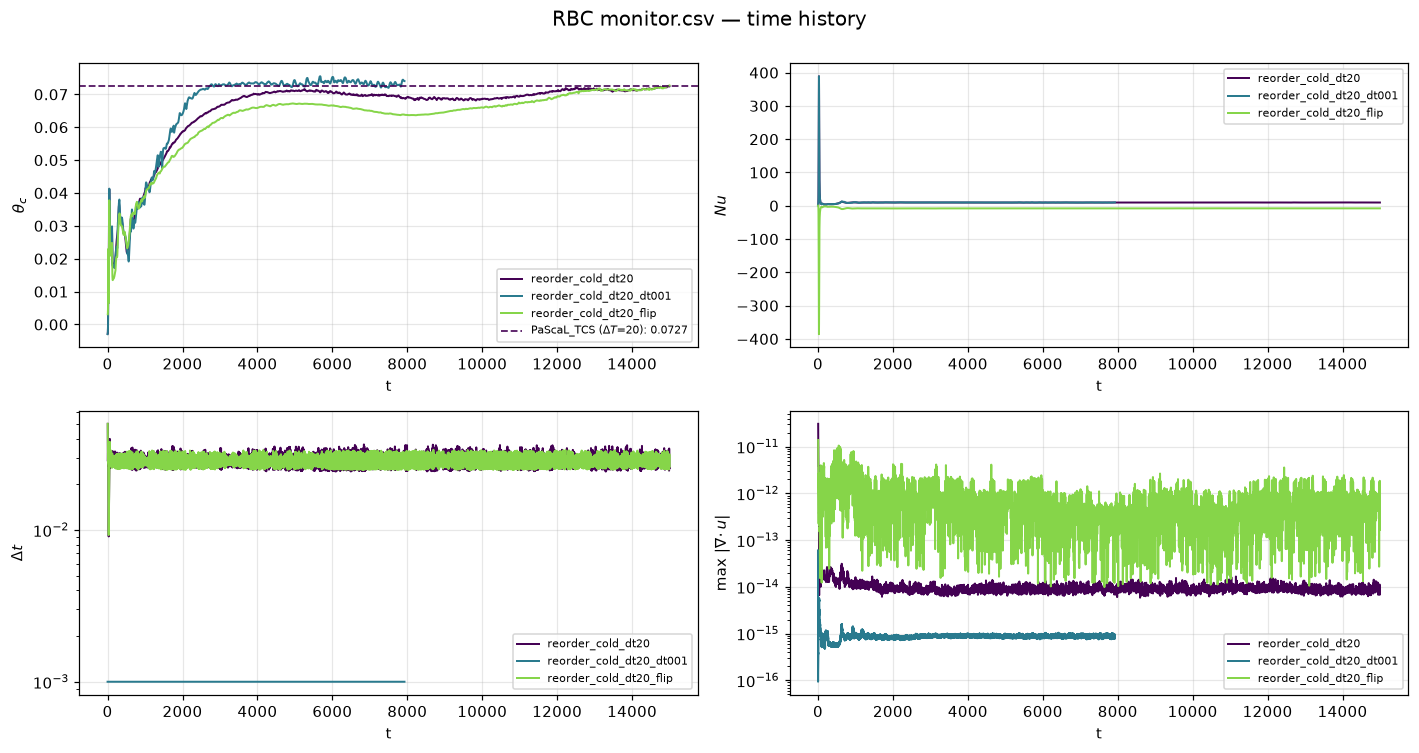

In [9]:
quantities = [
    ('Theta_c', r'$\theta_c$',              False),
    ('Nu',      r'$Nu$',                    False),
    ('dt',      r'$\Delta t$',              True),
    ('div',     r'max $|\nabla\!\cdot u|$', True),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 6.8))
axes = np.ravel(axes)

for ax, (key, ylabel, logy) in zip(axes, quantities):
    for name, case in cases.items():
        monitor = case['monitor']
        if monitor is None or key not in monitor.dtype.names:
            continue
        data = monitor[monitor['Theta_c'] != 0] if key == 'Theta_c' else monitor
        x = data[X_AXIS] if X_AXIS in data.dtype.names else data['step']
        ax.plot(x, data[key], color=case_colors[name], lw=1.3, label=name)
    if logy:
        ax.set_yscale('log')
    ax.set_xlabel(X_AXIS)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=7)

# Theta_c 패널: 각 ΔT마다 PaScaL_TCS 참조선 (해당 케이스 색의 파선, 같은 ΔT는 한 번만)
theta_axis = axes[0]
pascal_data = references.get('PaScaL_TCS')
drawn_targets = set()
if pascal_data is not None:
    for name, case in cases.items():
        stats = case['stats']
        if stats is None or 'DeltaT' not in stats:
            continue
        target = stats['DeltaT']
        if target in drawn_targets:
            continue
        drawn_targets.add(target)
        pascal_theta = np.interp(target, pascal_data[:, 0], pascal_data[:, 1]) / target
        theta_axis.axhline(pascal_theta, color=case_colors[name],
                           ls='--', lw=1.2, alpha=0.9,
                           label=rf'PaScaL_TCS ($\Delta T$={target:g}): {pascal_theta:.4f}')
theta_axis.legend(fontsize=7)

fig.suptitle('RBC monitor.csv — time history', fontsize=13, y=1.0)
fig.tight_layout()
plt.show()


## 2. stats_final.dat — z 프로파일 (케이스 비교)

케이스들이 가진 **모든 프로파일 변수의 합집합**으로 패널을 만들고 케이스를 겹쳐 그린다.
구 포맷 케이스는 `T_mean`, `W_rms` 패널에만 나타난다. `T_mean` 패널의 마커는 중앙(z=0.5) 보간값 $\theta_c$.

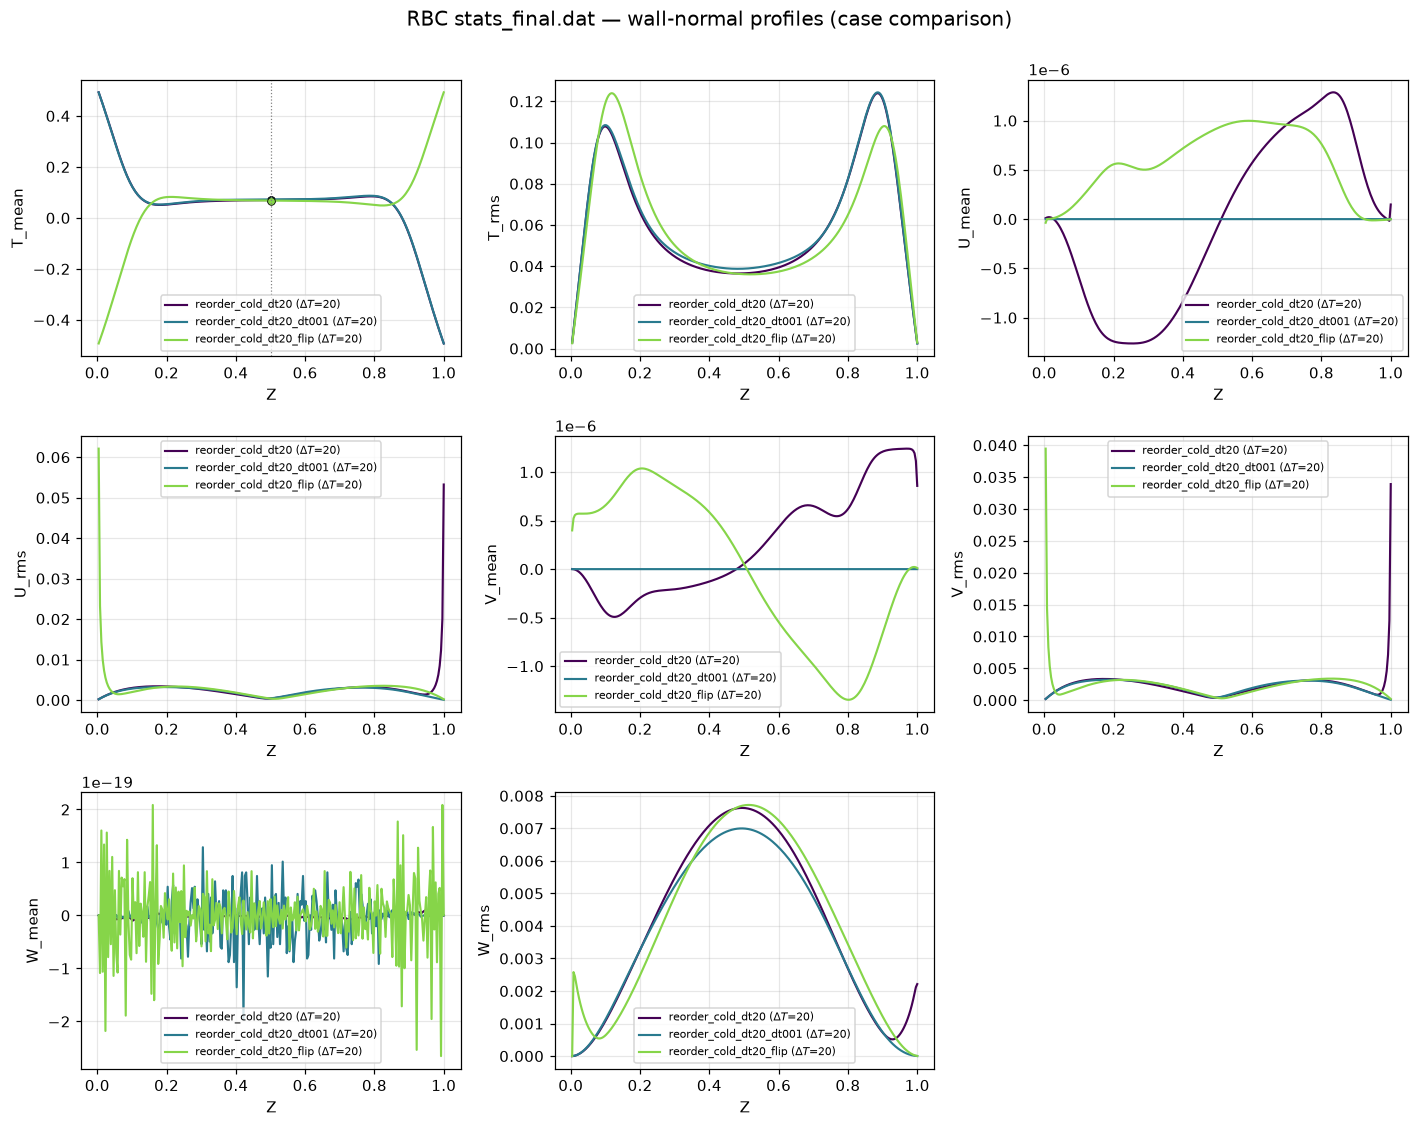

In [10]:
# 케이스들이 가진 프로파일 변수의 합집합 (Z 제외, 등장 순서 유지)
profile_vars = []
for case in cases.values():
    if case['stats'] is not None:
        for v in case['stats']['vars']:
            if v != 'Z' and v not in profile_vars:
                profile_vars.append(v)

ncols = 3
nrows = (len(profile_vars) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.4 * nrows), squeeze=False)
axes = np.ravel(axes)

for ax, v in zip(axes, profile_vars):
    for name, case in cases.items():
        stats = case['stats']
        if stats is None or v not in stats['data']:
            continue
        label = name
        if 'DeltaT' in stats:
            label += rf' ($\Delta T$={stats["DeltaT"]:g})'
        ax.plot(stats['data']['Z'], stats['data'][v],
                color=case_colors[name], lw=1.4, label=label)
        if v == 'T_mean':
            ax.plot(0.5, theta_center_of(stats), 'o', ms=5,
                    color=case_colors[name], mec='k', mew=0.5)
    if v == 'T_mean':
        ax.axvline(0.5, color='gray', ls=':', lw=0.8)
    ax.set_xlabel('Z')
    ax.set_ylabel(v)
    ax.legend(fontsize=7)

for ax in axes[len(profile_vars):]:
    ax.set_visible(False)

for name, case in cases.items():
    if case['stats'] is None:
        print(f'{name}: stats_final.dat 없음 — 건너뜀')

fig.suptitle('RBC stats_final.dat — wall-normal profiles (case comparison)', fontsize=13, y=1.0)
fig.tight_layout()
plt.show()

## 2b. 케이스별 통계 수렴 — 중간 stats 파일 겹쳐 그리기

각 케이스의 중간 `stats_t*.dat`(신형) / `stats_<step>.dat`(구형)와 `stats_final.dat`를
한 그림에 겹쳐 그려 통계가 수렴했는지 확인한다. 중간 파일이 없는 케이스는 건너뛴다.

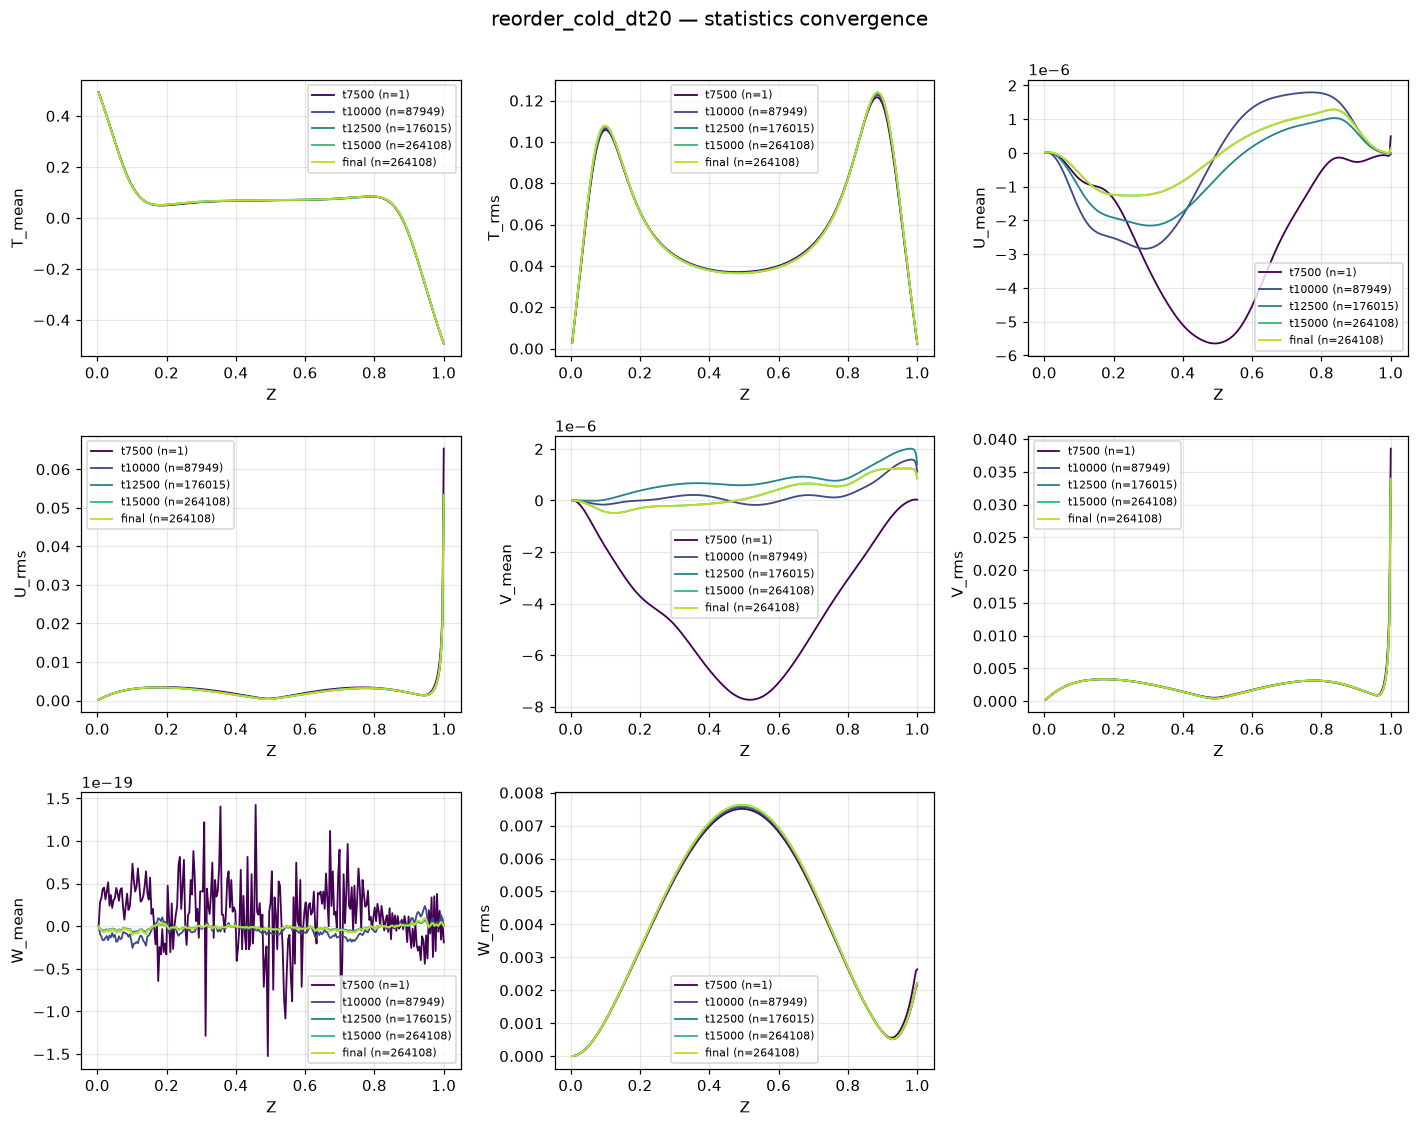

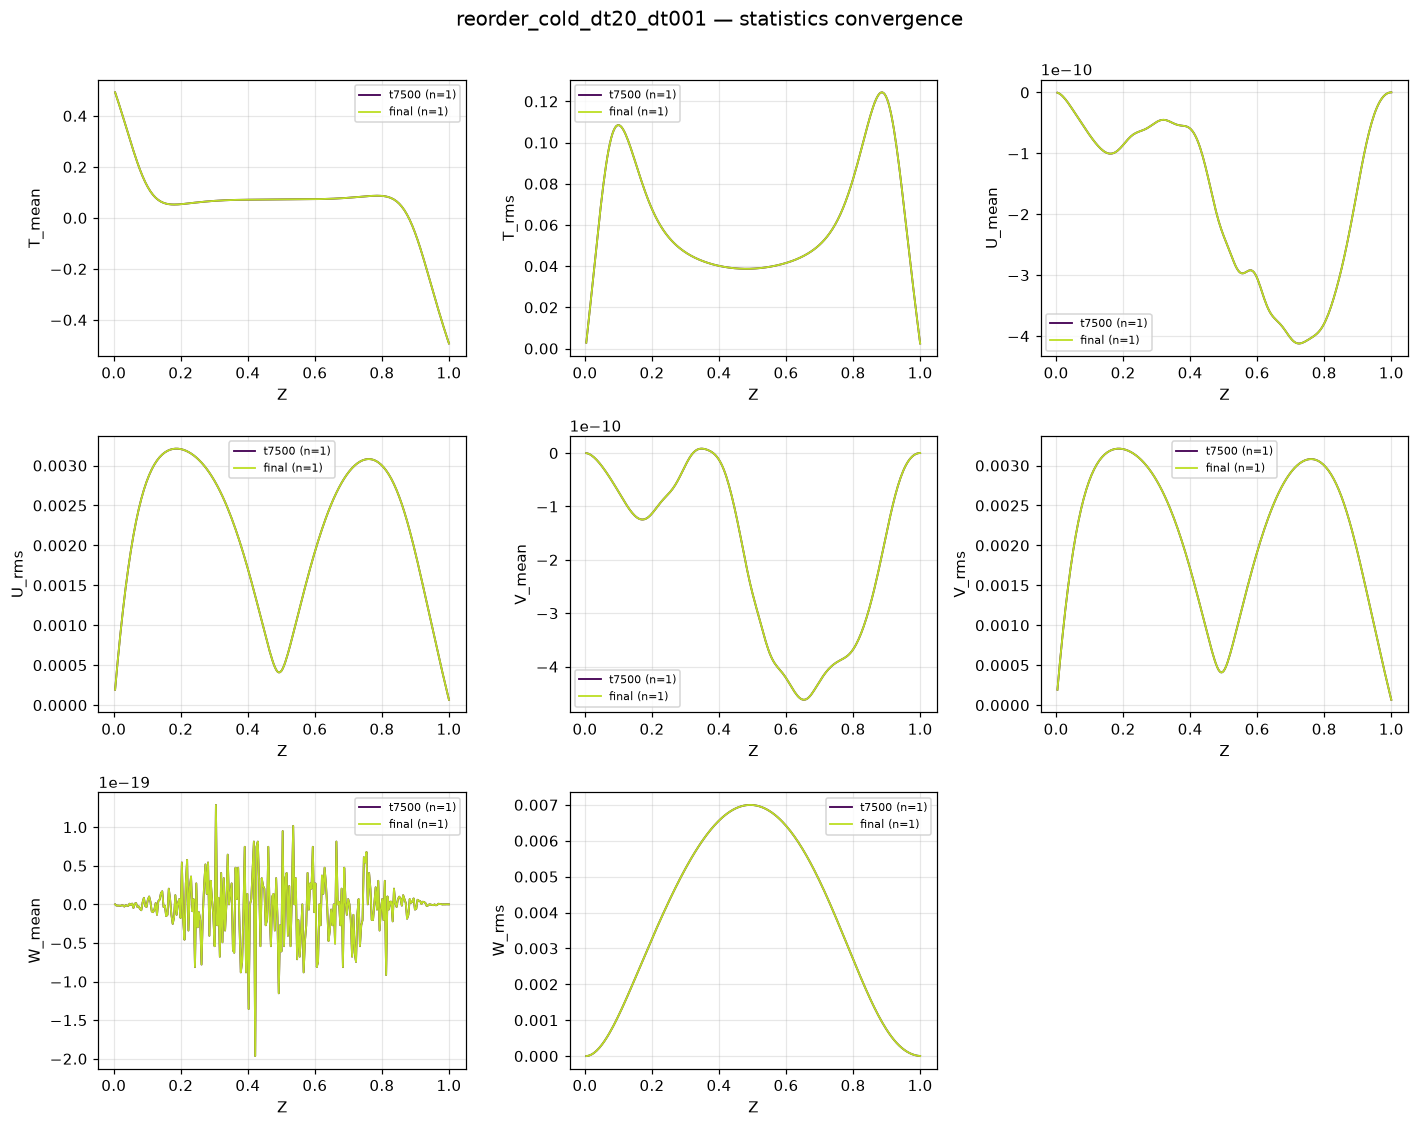

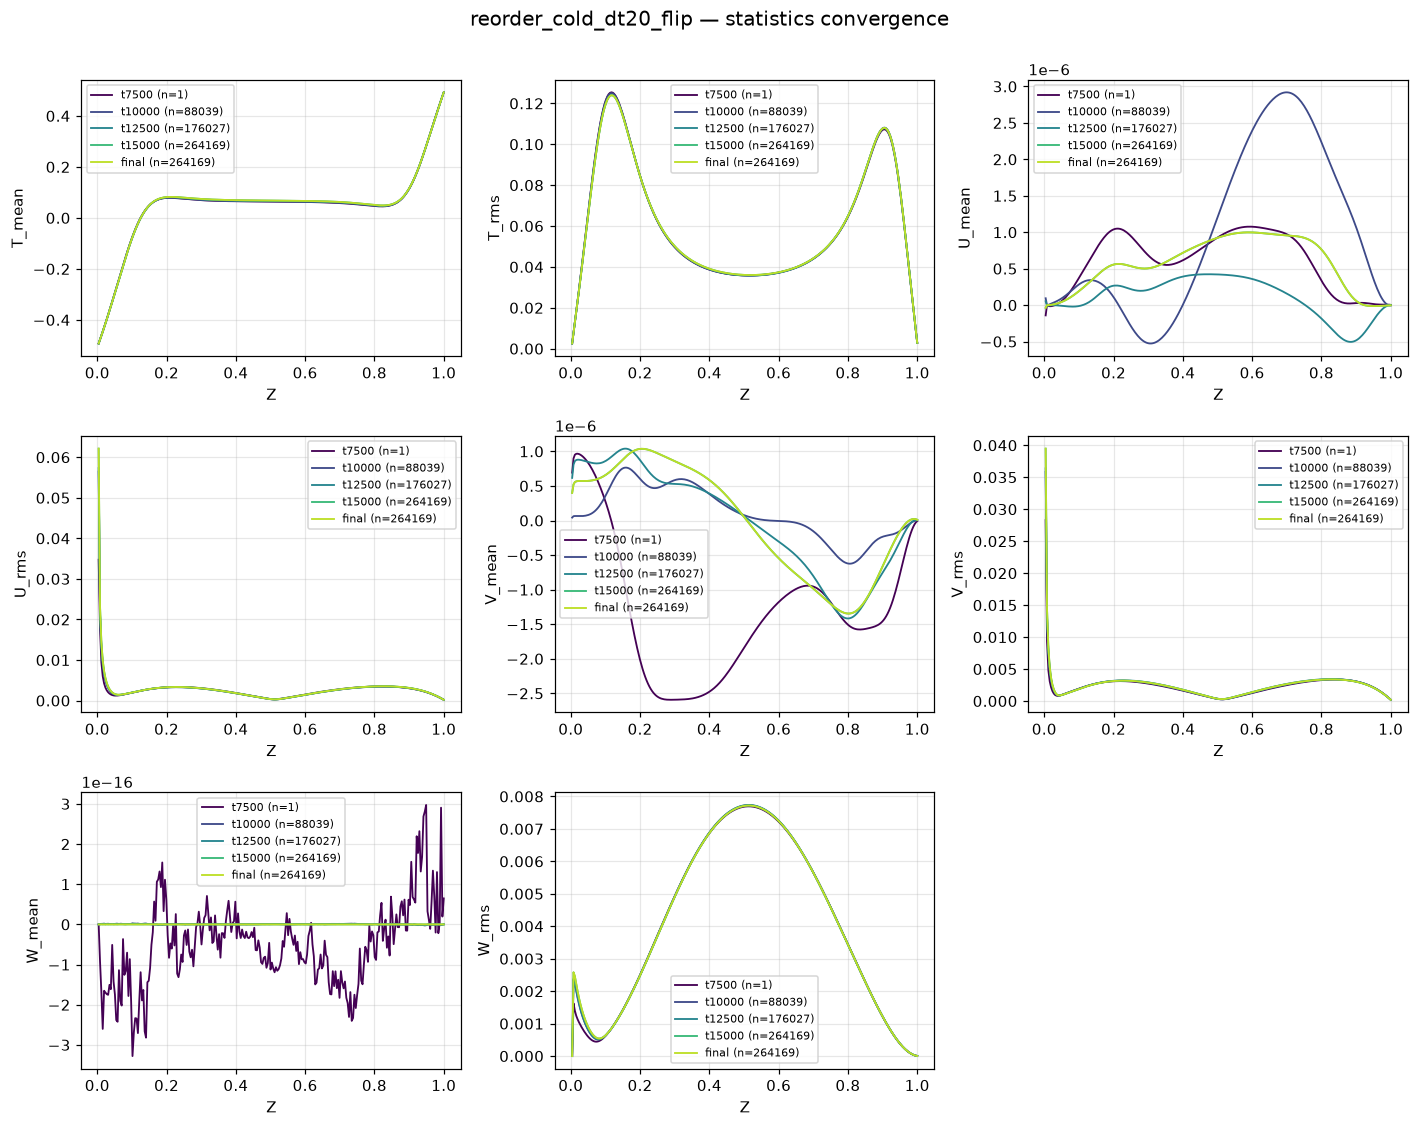

In [11]:
def plot_case_history(name, stats_list):
    if len(stats_list) < 2:
        print(f'{name}: 중간 stats 파일 없음 — 건너뜀')
        return
    profile_vars = [v for v in stats_list[-1]['vars'] if v != 'Z']
    ncols = 3
    nrows = (len(profile_vars) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.4 * nrows), squeeze=False)
    axes = np.ravel(axes)

    history_colors = plt.cm.viridis(np.linspace(0, 0.9, len(stats_list)))
    for ax, v in zip(axes, profile_vars):
        for stats, color in zip(stats_list, history_colors):
            if v not in stats['data']:
                continue
            ax.plot(stats['data']['Z'], stats['data'][v], lw=1.2, color=color,
                    label=f"{stats['tag']} (n={stats.get('n', 0)})")
        ax.set_xlabel('Z')
        ax.set_ylabel(v)
        ax.legend(fontsize=7)
    for ax in axes[len(profile_vars):]:
        ax.set_visible(False)

    fig.suptitle(f'{name} — statistics convergence', fontsize=13, y=1.0)
    fig.tight_layout()
    plt.show()


for name, case in cases.items():
    plot_case_history(name, case['stats_history'])

## 3. Fig.9 검증 — $\Delta T$ vs $\theta_c\cdot\Delta T$

각 케이스의 중앙(z=0.5) $T_{mean}$에 헤더의 $\Delta T$를 곱해 참조 데이터와 비교하고,
같은 $\Delta T$로 보간한 참조 대비 오차(%)를 출력한다.

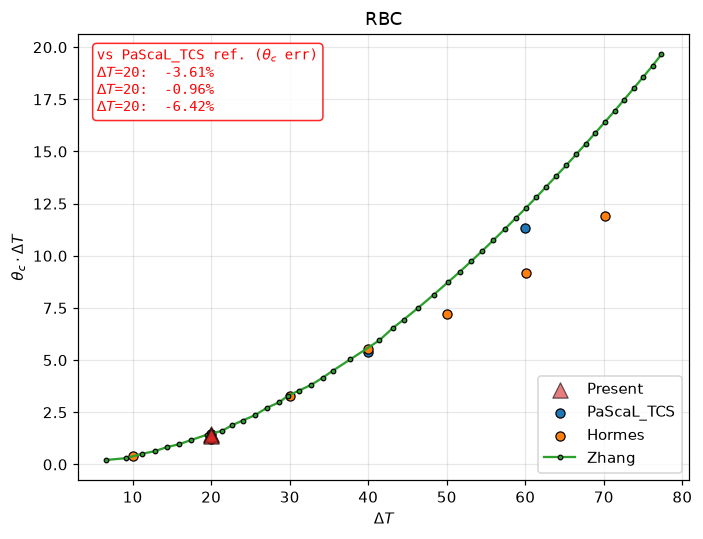

=== θ_c 비교 (참조는 같은 ΔT로 보간) ===
  ΔT=20: present θ_c=0.0700 | PaScaL_TCS 0.0727 (-3.61%) | Hormes 0.0611 (+14.55%) | Zhang 0.0738 (-5.16%)
  ΔT=20: present θ_c=0.0720 | PaScaL_TCS 0.0727 (-0.96%) | Hormes 0.0611 (+17.70%) | Zhang 0.0738 (-2.55%)
  ΔT=20: present θ_c=0.0680 | PaScaL_TCS 0.0727 (-6.42%) | Hormes 0.0611 (+11.21%) | Zhang 0.0738 (-7.92%)


In [12]:
reference_markers = {'Zhang': 'o', 'Ahlers': 's', 'Horn': 'D'}

present_targets, present_values = [], []
for name, case in cases.items():
    stats = case['stats']
    if stats is None or 'DeltaT' not in stats:
        continue
    present_targets.append(stats['DeltaT'])
    present_values.append(theta_center_of(stats) * stats['DeltaT'])

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(present_targets, present_values, s=100, marker='^',
           c='tab:red', edgecolors='black', linewidths=0.8, alpha=0.6,
           zorder=5, label='Present')

for reference_name, reference_data in references.items():
    marker = reference_markers.get(reference_name, 'o')
    color = reference_colors[reference_name]
    if reference_name == 'Zhang':
        ax.plot(reference_data[:, 0], reference_data[:, 1],
                color=color, marker=marker, markersize=3,
                markerfacecolor=color, markeredgecolor='black',
                markeredgewidth=0.8, zorder=4, label=reference_name)
    else:
        ax.scatter(reference_data[:, 0], reference_data[:, 1],
                   c=color, marker=marker,
                   edgecolors='black', linewidths=0.8,
                   zorder=4, label=reference_name)

ax.set_xlabel(r'$\Delta T$')
ax.set_ylabel(r'$\theta_c \cdot \Delta T$')
ax.set_title("RBC")
ax.legend()

# --- PaScaL_TCS 참조 대비 θ_c 오차를 Figure 안에 빨간 글자로 표시 ---
# (in-figure 텍스트는 mathtext/ASCII만 사용 — matplotlib 기본 폰트 한글 미지원 회피)
pascal_data = references.get('PaScaL_TCS')
if pascal_data is not None and present_targets:
    error_lines = [r'vs PaScaL_TCS ref. ($\theta_c$ err)']
    for target, value in zip(present_targets, present_values):
        reference_theta = np.interp(target, pascal_data[:, 0], pascal_data[:, 1]) / target
        error = (value / target - reference_theta) / reference_theta * 100
        error_lines.append(rf'$\Delta T$={target:g}:  {error:+.2f}%')
    ax.text(0.03, 0.97, '\n'.join(error_lines),
            transform=ax.transAxes, color='red', fontsize=9,
            va='top', ha='left', family='monospace',
            bbox=dict(boxstyle='round', facecolor='white',
                      edgecolor='red', alpha=0.85))

fig.tight_layout()
plt.show()

print('=== θ_c 비교 (참조는 같은 ΔT로 보간) ===')
for target, value in zip(present_targets, present_values):
    parts = [f'ΔT={target:g}: present θ_c={value / target:.4f}']
    for reference_name, reference_data in references.items():
        reference_theta = np.interp(target, reference_data[:, 0], reference_data[:, 1]) / target
        error = (value / target - reference_theta) / reference_theta * 100
        parts.append(f'{reference_name} {reference_theta:.4f} ({error:+.2f}%)')
    print('  ' + ' | '.join(parts))